<a href="https://colab.research.google.com/github/jerexinho1/salesinsight-py/blob/feat%2Fpipeline-dados/salesinsight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
SalesInsight PY
Analisador de dados de vendas
"""
import json
import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
import os


# ---------------------------------------------------------------
# RF01 - Gerar o dataset de vendas
# ---------------------------------------------------------------
def gerar_dataset_vendas(n_registros=200, seed=42):
    """Gera um dataset sintetico de vendas com dados sujos."""

    # Controla a aleatoriedade para o resultado ser sempre o mesmo
    random.seed(seed)
    np.random.seed(seed)

    # Produtos disponiveis
    produtos = ["Notebook", "Smartphone", "Tablet", "Monitor",
                "Teclado", "Mouse", "Headset"]

    # Relacao entre produtos e categorias
    categorias = {"Notebook": "Computadores", "Smartphone": "Celulares",
                  "Tablet": "Celulares", "Monitor": "Computadores",
                  "Teclado": "Perifericos", "Mouse": "Perifericos",
                  "Headset": "Perifericos"}

    # Preco base de cada produto
    precos = {"Notebook": 3500, "Smartphone": 2200, "Tablet": 1800,
              "Monitor": 1200, "Teclado": 250, "Mouse": 120,
              "Headset": 350}

    # Regioes de venda
    regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]

    # Data inicial
    data_inicio = datetime(2025, 1, 1)

    # Lista vazia onde guardamos as vendas
    dados = []

    # Gera as vendas
    for i in range(n_registros):
        produto = random.choice(produtos)
        categoria = categorias[produto]
        quantidade = random.randint(1, 10)
        preco = round(precos[produto] * random.uniform(0.85, 1.15), 2)
        data = data_inicio + timedelta(days=random.randint(0, 364))
        data_txt = data.strftime("%Y-%m-%d")
        cliente = f"Cliente_{random.randint(1, 50):03d}"

        # Sujeira proposital: algumas datas invalidas
        if random.random() < 0.03:
            data_txt = "DATA INVALIDA"

        # Adiciona a venda a lista
        dados.append({
            "id_venda": i + 1,
            "data_venda": data_txt,
            "cliente": cliente,
            "produto": produto,
            "categoria": categoria,
            "regiao": random.choice(regioes),
            "quantidade": quantidade,
            "preco_unitario": preco,
        })

    # Converte a lista em DataFrame
    return pd.DataFrame(dados)


# ---------------------------------------------------------------
# RF02 - Inspecionar e descrever os dados
# ---------------------------------------------------------------
def inspecionar_dados(df):
    """Exibe as informacoes estruturais do DataFrame."""
    print("\n=== INSPECAO INICIAL DO DATASET ===")
    print(f"Shape: {df.shape}")
    print(f"\nColunas: {list(df.columns)}")
    print(f"\nTipos de dados:\n{df.dtypes}")
    print(f"\nValores nulos por coluna:\n{df.isnull().sum()}")
    print(f"\nPrimeiros registros:\n{df.head()}")
    return df


# ---------------------------------------------------------------
# RF03 - Tratar os dados (datetime)
# ---------------------------------------------------------------
def tratar_dados(df):
    """
    Trata o DataFrame de vendas.
    Retorna: (df_limpo, relatorio), onde relatorio e um dicionario
    com as contagens de registros iniciais, convertidos e finais.
    """
    # Trabalha em uma copia para nao alterar o DataFrame original
    df = df.copy()
    registros_iniciais = len(df)

    # 1. Remover espacos extras nas colunas de texto
    colunas_texto = ["data_venda", "cliente", "produto", "categoria", "regiao"]
    for coluna in colunas_texto:
        df[coluna] = df[coluna].str.strip()

    # 2. Converter data_venda e descartar datas invalidas
    df["data_venda"] = pd.to_datetime(df["data_venda"], errors="coerce")
    datas_invalidas = int(df["data_venda"].isnull().sum())
    df = df.dropna(subset=["data_venda"])

    # 3. Ajustar os tipos numericos
    qtd_ja_correta = pd.api.types.is_integer_dtype(df["quantidade"])
    preco_ja_correto = pd.api.types.is_float_dtype(df["preco_unitario"])
    df["quantidade"] = df["quantidade"].astype(int)
    df["preco_unitario"] = df["preco_unitario"].astype(float)

    # 4. Montar e imprimir o relatorio de limpeza
    registros_finais = len(df)
    relatorio = {
        "registros_iniciais": registros_iniciais,
        "datas_convertidas": registros_finais,
        "datas_invalidas_removidas": datas_invalidas,
        "registros_finais": registros_finais,
        "colunas_numericas_sem_alteracao": int(qtd_ja_correta) + int(preco_ja_correto),
    }

    print("\n=== RELATORIO DE LIMPEZA ===")
    print(f"Registros que entraram: {relatorio['registros_iniciais']}")
    print(f"Datas convertidas (texto -> datetime): {relatorio['datas_convertidas']}")
    print(f"Registros removidos por data invalida: {relatorio['datas_invalidas_removidas']}")
    print(f"Colunas numericas que ja estavam corretas: {relatorio['colunas_numericas_sem_alteracao']} de 2")
    print(f"Registros que permaneceram: {relatorio['registros_finais']}")

    return df, relatorio


# ---------------------------------------------------------------
# RF04 - Criar colunas derivadas
# ---------------------------------------------------------------
MESES_PT = {
    1: "Janeiro", 2: "Fevereiro", 3: "Marco", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro",
}


def criar_colunas_derivadas(df):
    """Cria colunas de receita, data e faixa de receita."""
    df = df.copy()

    # Receita da linha (operacao vetorizada, sem loop)
    df["receita_total"] = df["quantidade"] * df["preco_unitario"]

    # Componentes da data
    df["mes"] = df["data_venda"].dt.month
    df["mes_nome"] = df["mes"].map(MESES_PT)
    df["trimestre"] = "Q" + df["data_venda"].dt.quarter.astype(str)
    df["ano"] = df["data_venda"].dt.year

    # Faixa de receita (transformacao condicional)
    condicoes = [
        df["receita_total"] < 500,
        (df["receita_total"] >= 500) & (df["receita_total" ] < 5000),
        df["receita_total"] >= 5000,
    ]
    faixas = ["Baixo Valor", "Medio Valor", "Alto Valor"]
    df["faixa_receita_item"] = "Nao Classificado"
    for condicao, faixa in zip(condicoes, faixas):
        df.loc[condicao, "faixa_receita_item"] = faixa

    return df

# ---------------------------------------------------------------
# RF05 - Calcular metricas agregadas
# ---------------------------------------------------------------
def calcular_metricas(df):
    """
    Calcula as metricas agregadas do dataset.
    Retorna um dicionario no formato {nome_da_metrica: DataFrame}.
    """
    metricas = {}

    # Receita, quantidade e numero de vendas por mes
    metricas["por_mes"] = (
        df.groupby("mes")
        .agg(receita_total=("receita_total", "sum"),
             quantidade=("quantidade", "sum"),
             n_vendas=("id_venda", "count"))
        .reset_index()
    )

    # Top 5 produtos por receita
    metricas["top_produtos"] = (
        df.groupby("produto")["receita_total"].sum()
        .sort_values(ascending=False)
        .head(5)
        .reset_index()
    )

    # Receita por categoria
    metricas["por_categoria"] = (
        df.groupby("categoria")["receita_total"].sum()
        .sort_values(ascending=False)
        .reset_index()
    )

    # Receita total e ticket medio por regiao
    metricas["por_regiao"] = (
        df.groupby("regiao")
        .agg(receita_total=("receita_total", "sum"),
             ticket_medio=("receita_total", "mean"))
        .sort_values("receita_total", ascending=False)
        .reset_index()
    )

    # Exibe cada metrica no console
    for nome, tabela in metricas.items():
        print(f"\n=== {nome.upper().replace('_', ' ')} ===")
        print(tabela.round(2).to_string(index=False))

    return metricas

# ---------------------------------------------------------------
# RF06 - Segmentar clientes por nivel de gasto
# ---------------------------------------------------------------
def segmentar_clientes(df):
    """
    Agrupa por cliente, soma a receita e classifica em
    Bronze / Prata / Ouro.
    Retorna um DataFrame com: cliente, total_gasto, segmento.
    """
    # Total gasto por cliente
    clientes = (
        df.groupby("cliente")["receita_total"].sum()
        .reset_index()
        .rename(columns={"receita_total": "total_gasto"})
    )

    # Classificacao com lambda + apply
    clientes["segmento"] = clientes["total_gasto"].apply(
        lambda g: "Ouro" if g > 15000 else ("Prata" if g >= 5000 else "Bronze")
    )

    # Ordena do maior para o menor gasto
    clientes = clientes.sort_values("total_gasto", ascending=False).reset_index(drop=True)

    print("\n=== TOP 10 CLIENTES ===")
    print(clientes.head(10).round(2).to_string(index=False))

    print("\n=== CLIENTES POR SEGMENTO ===")
    print(clientes["segmento"].value_counts().to_string())

    return clientes
# ---------------------------------------------------------------
# RF07 - Criar visualizacoes com Matplotlib
# ---------------------------------------------------------------
COR_PRINCIPAL = "#1F4E79"
CORES_CATEGORIA = {
    "Computadores": "#1F4E79",
    "Celulares": "#E07A1F",
    "Perifericos": "#3A8A5C",
}
MESES_ABREV = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]


def gerar_graficos(df, metricas, pasta="outputs/graficos"):
    """Gera e salva as quatro figuras do projeto em PNG."""
    os.makedirs(pasta, exist_ok=True)
    sns.set_theme(style="whitegrid")

    por_mes = metricas["por_mes"]
    top_produtos = metricas["top_produtos"]
    por_regiao = metricas["por_regiao"]

    # 1. Linha: receita por mes
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(por_mes["mes"], por_mes["receita_total"],
            marker="o", linewidth=2, color=COR_PRINCIPAL)
    ax.set_xticks(por_mes["mes"])
    ax.set_xticklabels(MESES_ABREV)
    ax.set_title("Receita Total por Mes (2025)")
    ax.set_xlabel("Mes")
    ax.set_ylabel("Receita Total (R$)")
    plt.tight_layout()
    plt.savefig(f"{pasta}/receita_por_mes.png", dpi=150)
    plt.close()

    # 2. Barras: top 5 produtos
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=top_produtos, y="produto", x="receita_total",
                hue="produto", legend=False, palette="Blues_r", ax=ax)
    ax.set_title("Top 5 Produtos por Receita")
    ax.set_xlabel("Receita Total (R$)")
    ax.set_ylabel("Produto")
    plt.tight_layout()
    plt.savefig(f"{pasta}/top_produtos.png", dpi=150)
    plt.close()

    # 3. Dispersao: quantidade x receita, colorido por categoria
    fig, ax = plt.subplots(figsize=(10, 6))
    for categoria, cor in CORES_CATEGORIA.items():
        dados = df[df["categoria"] == categoria]
        ax.scatter(dados["quantidade"], dados["receita_total"],
                   color=cor, label=categoria, alpha=0.7)
    ax.set_title("Quantidade x Receita por Venda")
    ax.set_xlabel("Quantidade Vendida")
    ax.set_ylabel("Receita da Venda (R$)")
    ax.legend(title="Categoria")
    plt.tight_layout()
    plt.savefig(f"{pasta}/quantidade_vs_receita.png", dpi=150)
    plt.close()

    # 4. Painel 2x2
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    axes[0, 0].plot(por_mes["mes"], por_mes["receita_total"],
                    marker="o", color=COR_PRINCIPAL)
    axes[0, 0].set_xticks(por_mes["mes"])
    axes[0, 0].set_xticklabels(MESES_ABREV)
    axes[0, 0].set_title("Receita por Mes")
    axes[0, 0].set_xlabel("Mes")
    axes[0, 0].set_ylabel("Receita (R$)")

    axes[0, 1].barh(top_produtos["produto"], top_produtos["receita_total"],
                    color=COR_PRINCIPAL)
    axes[0, 1].invert_yaxis()
    axes[0, 1].set_title("Top 5 Produtos")
    axes[0, 1].set_xlabel("Receita (R$)")
    axes[0, 1].set_ylabel("Produto")

    for categoria, cor in CORES_CATEGORIA.items():
        dados = df[df["categoria"] == categoria]
        axes[1, 0].scatter(dados["quantidade"], dados["receita_total"],
                           color=cor, label=categoria, alpha=0.7)
    axes[1, 0].set_title("Quantidade x Receita")
    axes[1, 0].set_xlabel("Quantidade")
    axes[1, 0].set_ylabel("Receita (R$)")
    axes[1, 0].legend(title="Categoria")

    axes[1, 1].bar(por_regiao["regiao"], por_regiao["receita_total"],
                   color="#3A8A5C")
    axes[1, 1].set_title("Receita por Regiao")
    axes[1, 1].set_xlabel("Regiao")
    axes[1, 1].set_ylabel("Receita (R$)")

    fig.suptitle("SalesInsight PY - Painel Resumo", fontsize=16)
    plt.tight_layout()
    plt.savefig(f"{pasta}/painel_resumo.png", dpi=150)
    plt.close()

    print(f"\n=== GRAFICOS ===\n4 figuras salvas em {pasta}/")

# ---------------------------------------------------------------
# RF08 - Funcao de ordem superior
# ---------------------------------------------------------------
def processar_coluna(df, coluna, funcao_transformacao, nome_saida=None):
    """
    Aplica uma funcao de transformacao a uma coluna do DataFrame.
    Demonstra o uso de funcoes como argumento (ordem superior).
    """
    df = df.copy()
    nome_saida = nome_saida or f"{coluna}_transformado"
    df[nome_saida] = df[coluna].apply(funcao_transformacao)
    return df

# ---------------------------------------------------------------
# RF08 - Classe que organiza o fluxo
# ---------------------------------------------------------------
class AnalisadorDeVendas:
    """Organiza o fluxo de analise de vendas em etapas."""

    def __init__(self):
        """Prepara os atributos vazios do analisador."""
        self.df_bruto = None
        self.df = None
        self.relatorio = None
        self.metricas = None
        self.clientes = None

    def carregar(self, caminho):
        """Le o CSV de vendas e guarda os dados brutos."""
        self.df_bruto = pd.read_csv(caminho)
        print(f"\n[CARREGAR] {len(self.df_bruto)} registros lidos de {caminho}")
        return self

    def transformar(self):
        """Limpa os dados e cria as colunas derivadas."""
        df_limpo, self.relatorio = tratar_dados(self.df_bruto)
        df = criar_colunas_derivadas(df_limpo)
        df = processar_coluna(df, "receita_total",
                              lambda x: round(x / 1000, 2),
                              nome_saida="receita_em_milhares")
        df = processar_coluna(df, "quantidade",
                              lambda q: "Alto Volume" if q > 5 else "Baixo Volume",
                              nome_saida="perfil_volume")
        self.df = df
        return self

    def analisar(self):
        """Calcula as metricas e segmenta os clientes."""
        self.metricas = calcular_metricas(self.df)
        self.clientes = segmentar_clientes(self.df)
        return self

    def visualizar(self):
        """Gera e salva os graficos."""
        gerar_graficos(self.df, self.metricas)
        return self

    def resumo(self):
        """Calcula e exibe as estatisticas gerais do periodo."""
        estatisticas = {
            "receita_total": round(self.df["receita_total"].sum(), 2),
            "numero_de_vendas": len(self.df),
            "ticket_medio": round(self.df["receita_total"].mean(), 2),
            "numero_de_clientes": self.df["cliente"].nunique(),
        }
        print("\n=== RESUMO GERAL ===")
        for chave, valor in estatisticas.items():
            print(f"{chave}: {valor}")
        return estatisticas

# ---------------------------------------------------------------
# RF09 - Exportar resultados em CSV e JSON
# ---------------------------------------------------------------
def exportar_resultados(metricas, clientes, estatisticas, pasta="outputs"):
    """Exporta as metricas e os clientes em CSV e o resumo em JSON."""
    os.makedirs(pasta, exist_ok=True)

    # Escrita em CSV
    metricas["por_mes"].to_csv(f"{pasta}/metricas_por_mes.csv",
                               index=False, encoding="utf-8-sig")
    clientes.to_csv(f"{pasta}/segmentacao_clientes.csv",
                    index=False, encoding="utf-8-sig")

    # Escrita em JSON
    serializavel = {k: round(float(v), 2) for k, v in estatisticas.items()}
    caminho = f"{pasta}/estatisticas_gerais.json"
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(serializavel, f, indent=4, ensure_ascii=False)

    # Leitura de volta para confirmar a escrita
    with open(caminho, "r", encoding="utf-8") as f:
        conferencia = json.load(f)

    print("\n=== EXPORTACAO ===")
    print(f"CSV salvo: {pasta}/metricas_por_mes.csv")
    print(f"CSV salvo: {pasta}/segmentacao_clientes.csv")
    print(f"JSON gravado e lido de volta: {conferencia}")
    return conferencia

# ---------------------------------------------------------------
# RF10 - Ponto de entrada: executa o fluxo completo
# ---------------------------------------------------------------
def main():
    """Executa o fluxo completo do SalesInsight PY."""
    print("=" * 60)
    print("   SALESINSIGHT PY - Analise de Dados de Vendas")
    print("=" * 60)

    # Etapa 0 - garantir a existencia do dataset
    if not os.path.exists("vendas.csv"):
        gerar_dataset_vendas().to_csv("vendas.csv", index=False)
        print("Dataset gerado e salvo em vendas.csv")

    # Etapas 1 a 6 - fluxo pela classe
    analisador = AnalisadorDeVendas()
    analisador.carregar("vendas.csv")
    inspecionar_dados(analisador.df_bruto)
    analisador.transformar()
    analisador.analisar()
    analisador.visualizar()
    estatisticas = analisador.resumo()

    # Etapa 7 - exportar os resultados
    exportar_resultados(analisador.metricas, analisador.clientes, estatisticas)

    print("\n[CONCLUIDO] Fluxo finalizado com sucesso.")


if __name__ == "__main__":
    main()

   SALESINSIGHT PY - Analise de Dados de Vendas

[CARREGAR] 200 registros lidos de vendas.csv

=== INSPECAO INICIAL DO DATASET ===
Shape: (200, 8)

Colunas: ['id_venda', 'data_venda', 'cliente', 'produto', 'categoria', 'regiao', 'quantidade', 'preco_unitario']

Tipos de dados:
id_venda            int64
data_venda         object
cliente            object
produto            object
categoria          object
regiao             object
quantidade          int64
preco_unitario    float64
dtype: object

Valores nulos por coluna:
id_venda          0
data_venda        0
cliente           0
produto           0
categoria         0
regiao            0
quantidade        0
preco_unitario    0
dtype: int64

Primeiros registros:
   id_venda     data_venda      cliente     produto     categoria    regiao  \
0         1     2025-05-21  Cliente_016       Mouse   Perifericos   Sudeste   
1         2  DATA INVALIDA  Cliente_003       Mouse   Perifericos       Sul   
2         3     2025-10-15  Cliente_013  

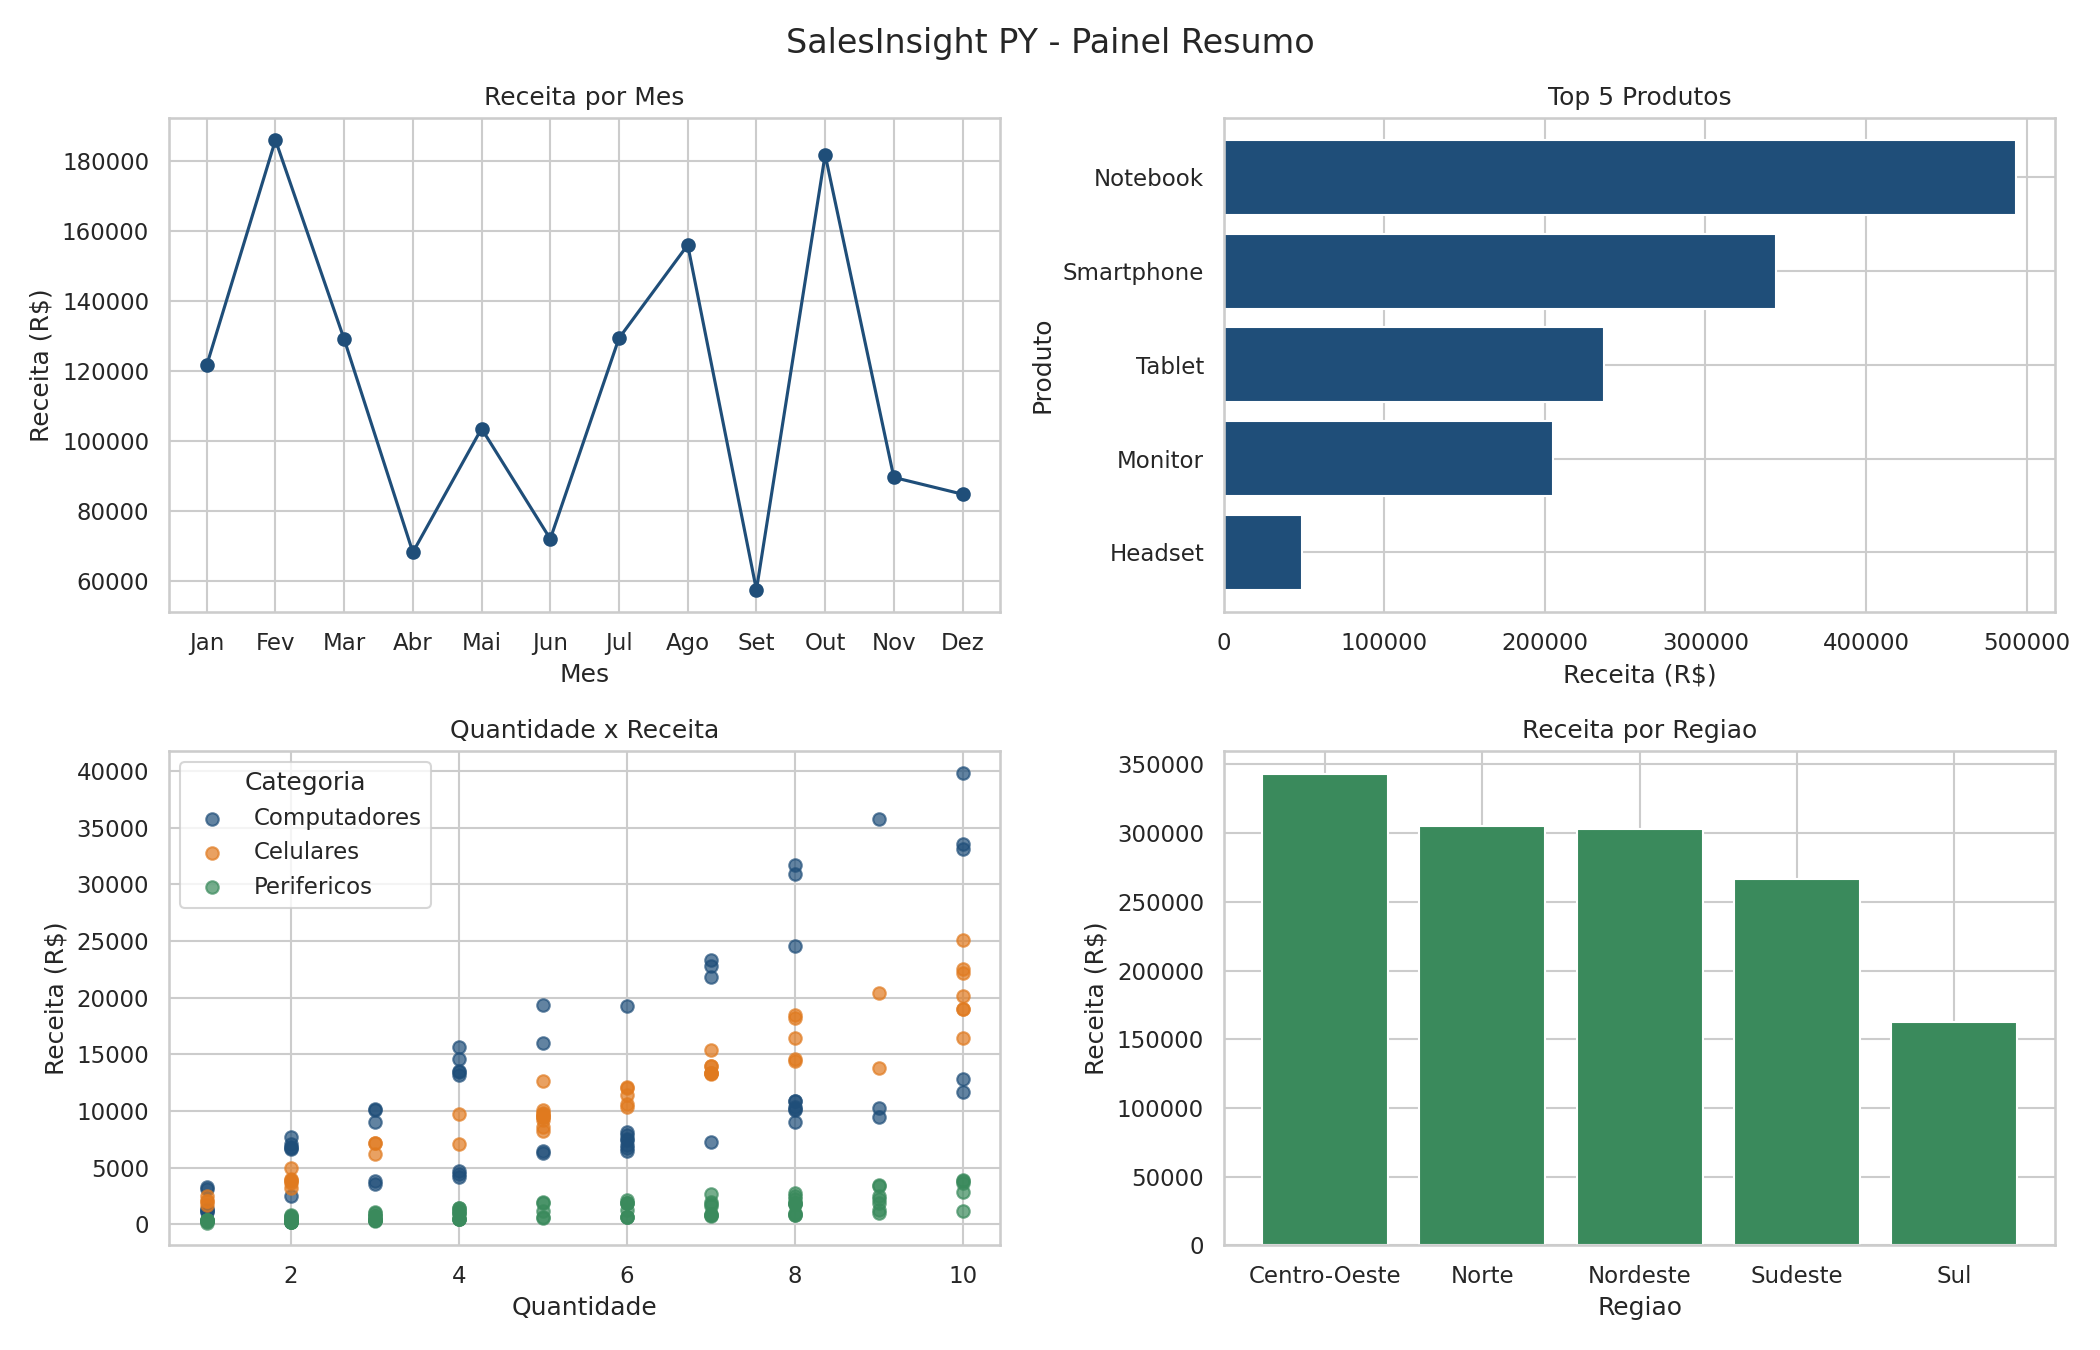

In [ ]:
from IPython.display import Image
Image("outputs/graficos/painel_resumo.png")